<center><h1>Prado_Mario_HW6</h1></center>

Name: Mario Prado
<br>
Github Username: mrpradooo
<br>
USC ID: 4223775338

## 1. Tree-Based Methods

Import packages

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, accuracy_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline   # applies SMOTE only when fitting

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
DATA = '../data'
SEED = 552
N_JOBS = -1

### (a) Download the APS Failure data

In [ ]:
def download(name):
    dataframe = pd.read_csv(os.path.join(DATA, name), skiprows=20, na_values='na')
    y = (dataframe.pop('class') == 'pos').astype(int).to_numpy()   # pos = 1
    return dataframe, y

X_train_raw, y_train = download('aps_failure_training_set.csv')
X_test_raw, y_test = download('aps_failure_test_set.csv')

FEATURES = list(X_train_raw.columns)
print('train:', X_train_raw.shape, ' test:', X_test_raw.shape, ' features:', len(FEATURES))

train: (60000, 170)  test: (16000, 170)  features: 170


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

So a couple techniques I found were filling with the mean, median, or mode, model-based imputation and deleting rows or columns with missing values. I decided to go with median imputation. I picked this one because deleting rows would cause us to lose too much data and the median is robust and can't be skewed so easily.

In [3]:
missing_data = X_train_raw.isna().mean().sort_values(ascending=False)
rows_with_holes = X_train_raw.isna().any(axis=1).mean()
print(f'rows with at least one missing value: {rows_with_holes:.1%}')
print(f'features with any missing value: {(missing_data > 0).sum()} of {len(FEATURES)}')
print('\nmost-missing features:')
print(missing_data.head(10).map('{:.1%}'.format).to_string())

rows with at least one missing value: 99.0%
features with any missing value: 169 of 170

most-missing features:
br_000    82.1%
bq_000    81.2%
bp_000    79.6%
bo_000    77.2%
ab_000    77.2%
cr_000    77.2%
bn_000    73.3%
bm_000    65.9%
bl_000    45.5%
bk_000    38.4%


In [ ]:
X_tra = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_train_raw), columns=FEATURES)
X_te = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_test_raw), columns=FEATURES)
print('missing after imputation:', int(X_tra.isna().sum().sum() + X_te.isna().sum().sum()))

missing after imputation: 0


#### (ii) Calculate the coefficient of variation

In [5]:
means = X_tra.mean()
coeffv_feat = (X_tra.std(ddof=1) / means).replace([np.inf, -np.inf], np.nan)
coeffv_feat = coeffv_feat.sort_values(ascending=False)
print(f'{coeffv_feat.isna().sum()} feature(s) with undefined CV (mean = 0):', list(coeffv_feat[coeffv_feat.isna()].index))
pd.set_option('display.max_rows', 200)
coeffv_feat.round(4).to_frame('CV')

0 feature(s) with undefined CV (mean = 0): []


,CV
cf_000,244.8875
co_000,244.5074
ad_000,244.3228
cs_009,237.9306
dh_000,123.2161
dj_000,117.4942
ag_000,92.9178
as_000,87.3325
ay_009,84.7337
ak_000,80.4250


#### (iii) Plot a correlation matrix

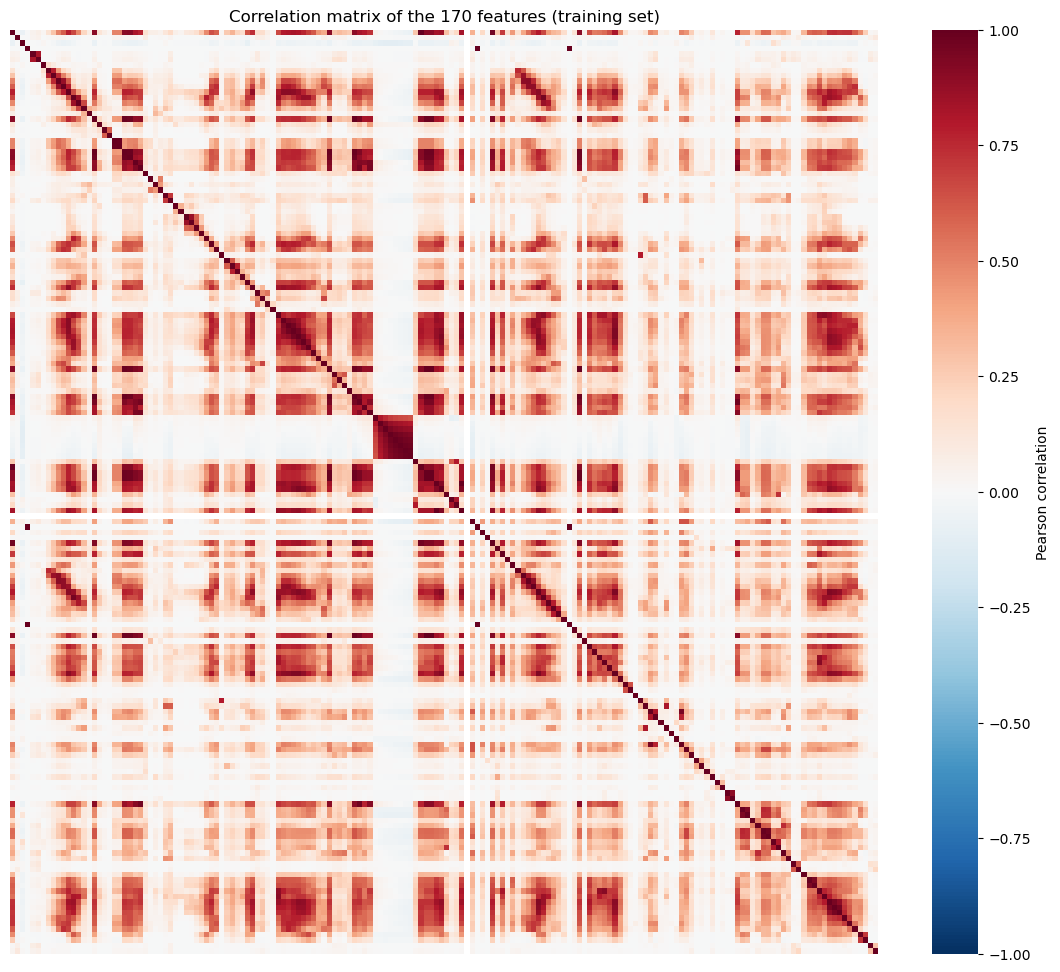

feature pairs with |r| > 0.9: 130


In [6]:
corr_matrix = X_tra.corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, xticklabels=False, yticklabels=False,
            cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation matrix of the 170 features (training set)')
plt.show()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
print('feature pairs with |r| > 0.9:', int((upper.abs() > 0.9).sum().sum()))

#### (iv) Make scatter plots and box plots

13 features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


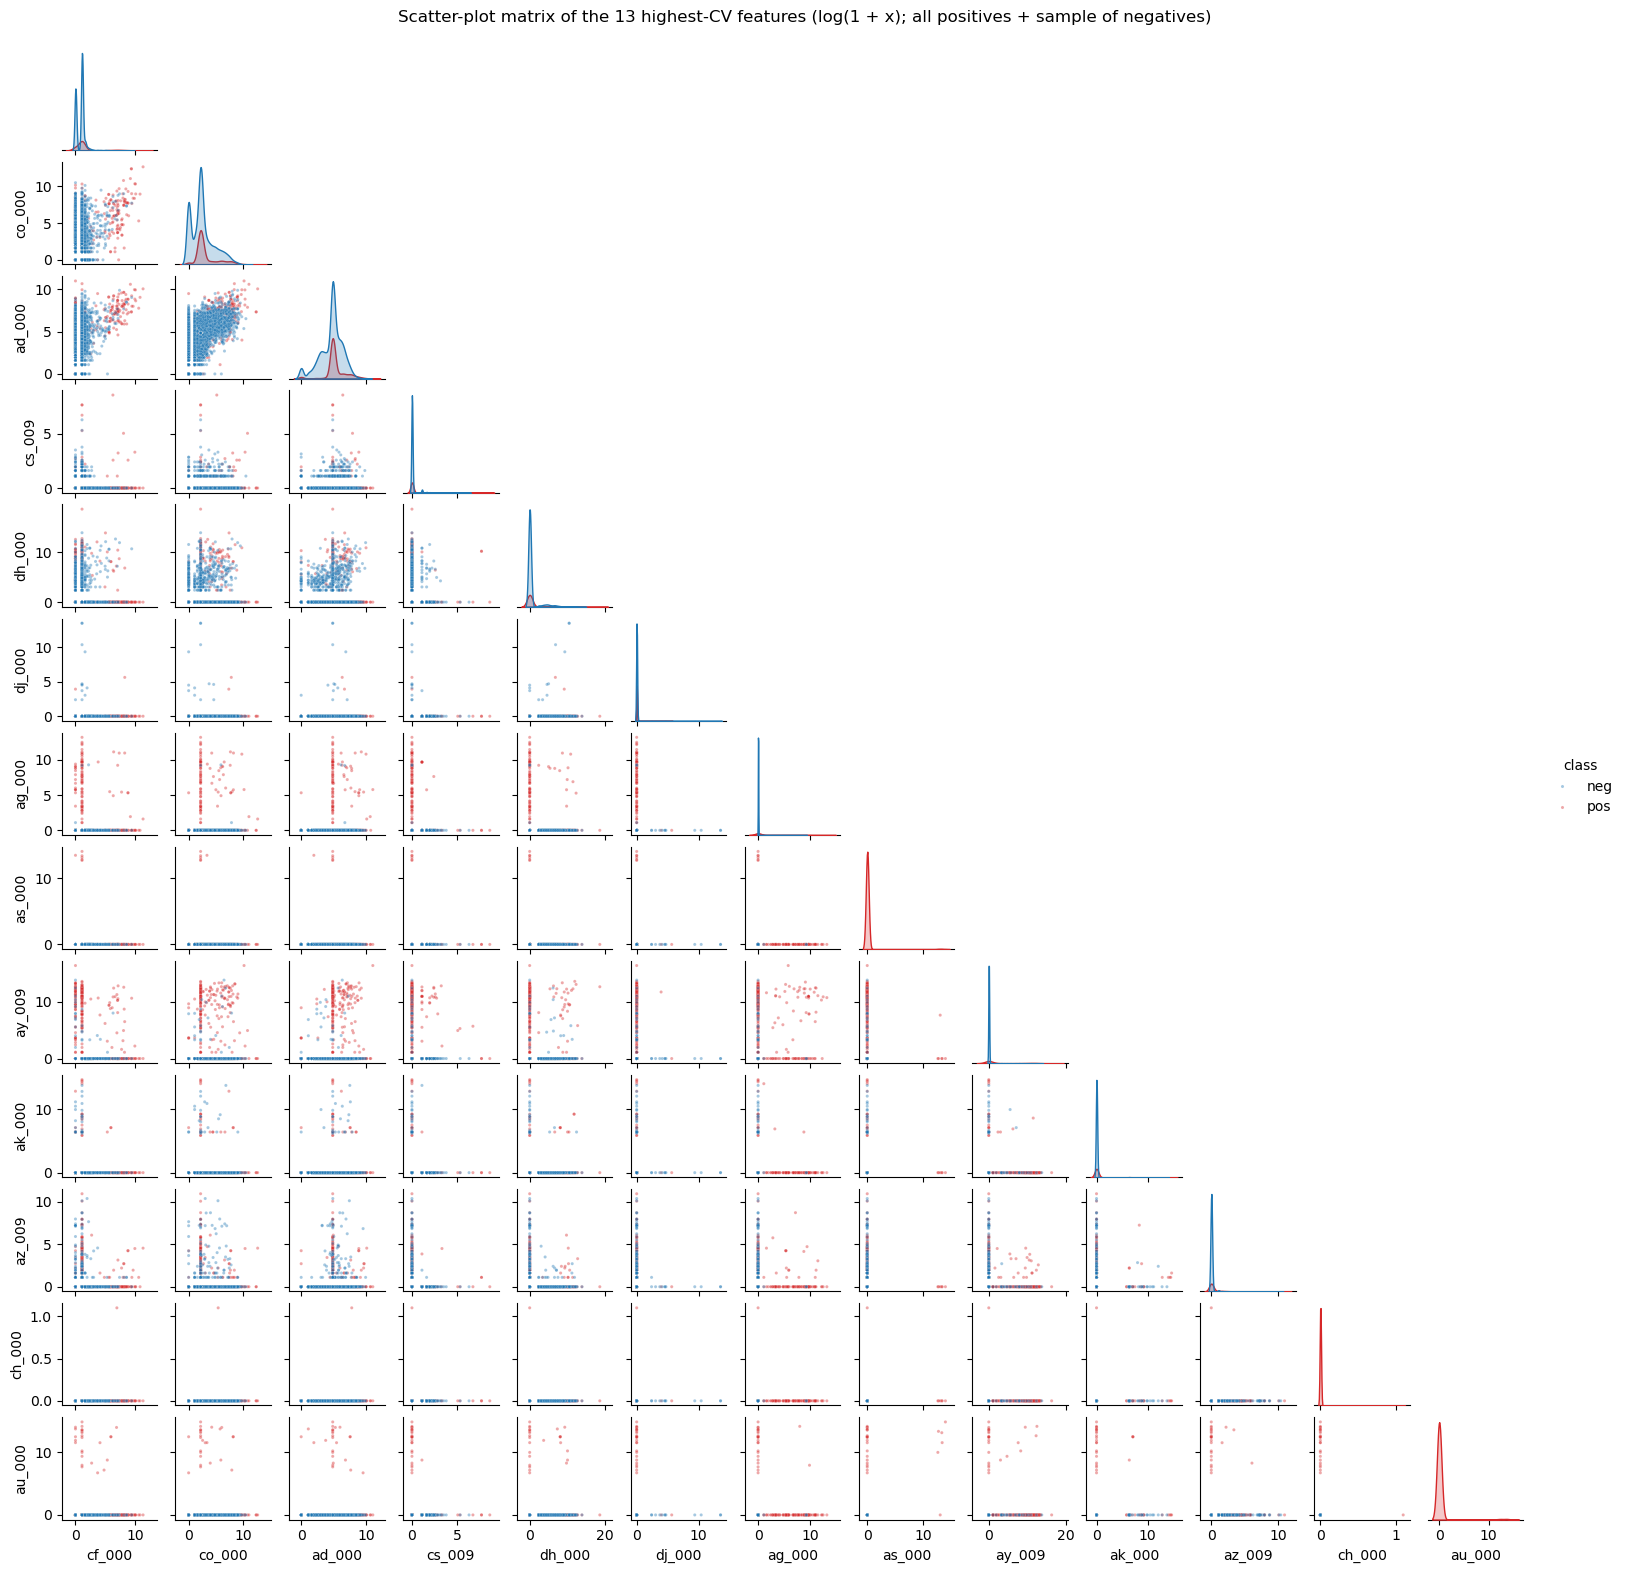

In [ ]:
k = int(np.floor(np.sqrt(170)))
top = coeffv_feat.dropna().head(k).index.tolist()
print(k, 'features:', top)

positive_idx = np.where(y_train == 1)[0]
negative_idx = np.random.default_rng(SEED).choice(np.where(y_train == 0)[0], size=min(4000, (y_train == 0).sum()), replace=False)
idx = np.r_[positive_idx, negative_idx]
plot_dataf = np.log1p(X_tra.iloc[idx][top].clip(lower=0))
plot_dataf['class'] = np.where(y_train[idx] == 1, 'pos', 'neg')
g = sns.pairplot(plot_dataf, hue='class', hue_order=['neg', 'pos'], palette={'neg': 'tab:blue', 'pos': 'tab:red'},
                 corner=True, height=1.2, plot_kws={'s': 5, 'alpha': .4})
g.fig.suptitle('Scatter-plot matrix of the 13 highest-CV features (log(1 + x); all positives + sample of negatives)', y=1.01)
plt.show()

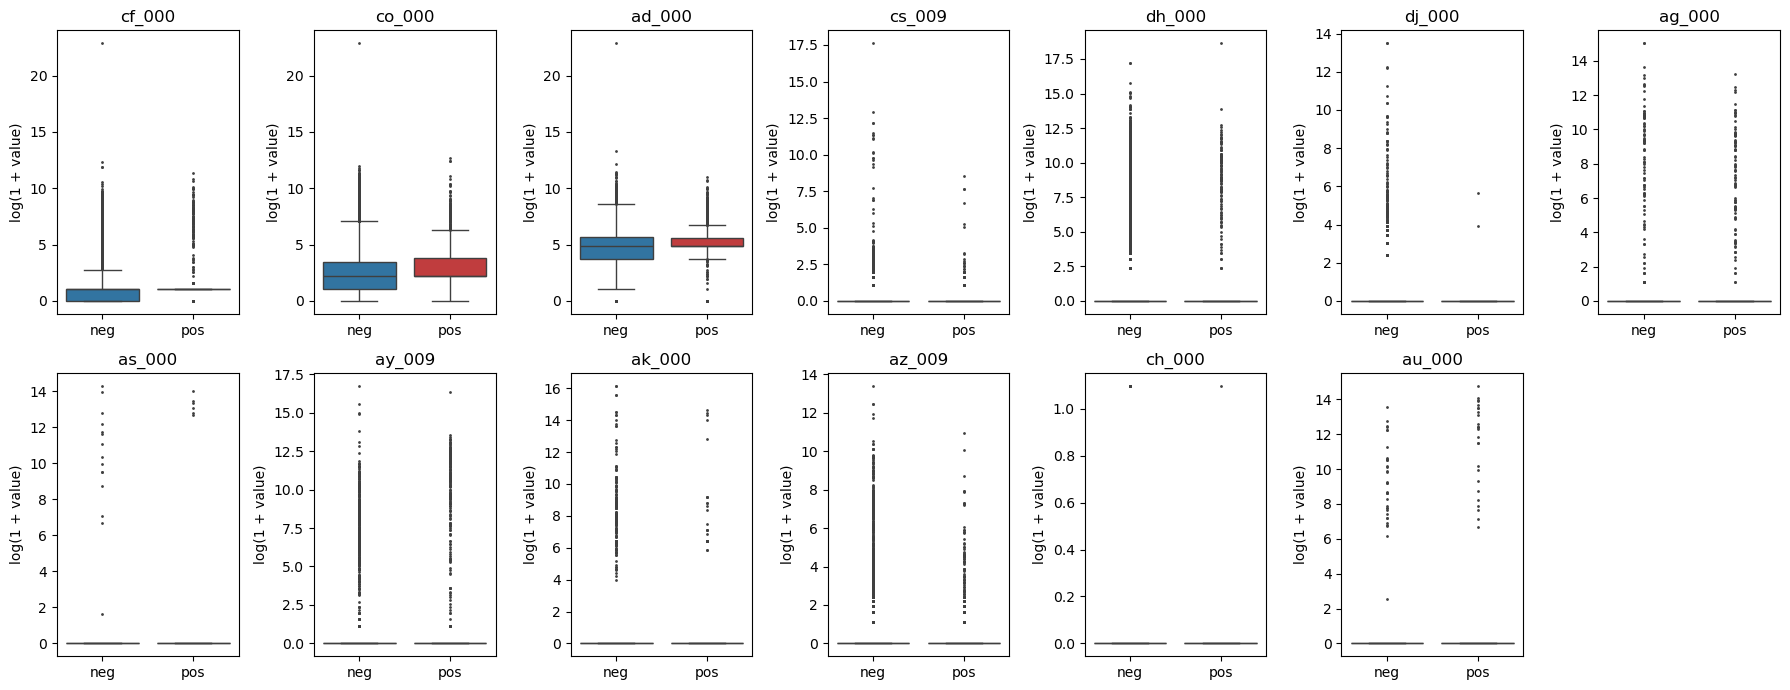

In [8]:
# box plots by class (log scale)
fig, axes = plt.subplots(2, 7, figsize=(18, 7))
for ax, f in zip(axes.ravel(), top):
    sns.boxplot(x=np.where(y_train == 1, 'pos', 'neg'), y=np.log1p(X_tra[f].clip(lower=0)), ax=ax,
                order=['neg', 'pos'], palette={'neg': 'tab:blue', 'pos': 'tab:red'}, fliersize=1)
    ax.set(title=f, xlabel='', ylabel='log(1 + value)')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

**No.** Scatter plots only show pairwise relationships, and a feature's significance depends on the other features in the model. A high CV also doesn't mean a feature is predictive: cf_000, co_000 and ad_000 top the list mainly because each has a single value of about 8.6 × 10⁹, and features like cs_009, dj_000 and ch_000 are 0 for almost every truck in both classes. The plots can only hint at useful features (positives tend to have larger values of ay_009, ag_000, co_000 and ad_000); significance has to be tested with a fitted model.


No, just based off the scatter plots themselves we cannot draw any significance. Scatter plots are really good at highlighting pairwise realtionships, meaing one on on, and the significance of a feature depends on the other features in the model. 

NOT DONE

#### (v) Is this data set imbalanced?

In [9]:
for name, y in [('train', y_train), ('test', y_test)]:
    print(f'{name}: positive = {y.sum():,}, negative = {(y == 0).sum():,}, positive share = {y.mean():.2%}')

train: positive = 1,000, negative = 59,000, positive share = 1.67%
test: positive = 375, negative = 15,625, positive share = 2.34%




Yes I would say the data is very imbalanced. We can see this because as in the training set there is only 1,000 postive and 59,000 negative. Same with the test set, 375 positive and 15,625 negative. So both sets are around only 2% positive so very imbalanced.

### (c) Train a random forest

In [ ]:

def evaluate(model, name):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
    out = {}
    for j, (split, X, y) in enumerate([('train', X_tra, y_train), ('test', X_te, y_test)]):
        probability = model.predict_proba(X)[:, 1]
        prediction = (probability >= 0.5).astype(int)
        conf_matrix = confusion_matrix(y, prediction)
        ConfusionMatrixDisplay(conf_matrix, display_labels=['neg', 'pos']).plot(ax=ax[j], colorbar=False, values_format='d')
        ax[j].set_title(f'{name}: {split} confusion matrix')
        fpr, tpr, _ = roc_curve(y, probability)
        auc = roc_auc_score(y, probability)
        ax[2].plot(fpr, tpr, label=f'{split} (AUC = {auc:.4f})')
        out[split] = {'AUC': auc, 'misclassification': 1 - accuracy_score(y, prediction),
                      'false negatives': int(conf_matrix[1, 0]), 'false positives': int(conf_matrix[0, 1])}
    ax[2].plot([0, 1], [0, 1], 'k--', lw=.8)
    ax[2].set(xlabel='false positive rate', ylabel='true positive rate', title=f'{name}: ROC'); ax[2].legend()
    plt.tight_layout(); plt.show()
    table = pd.DataFrame(out).T
    print(table.to_string())
    return table

trained in 43 s


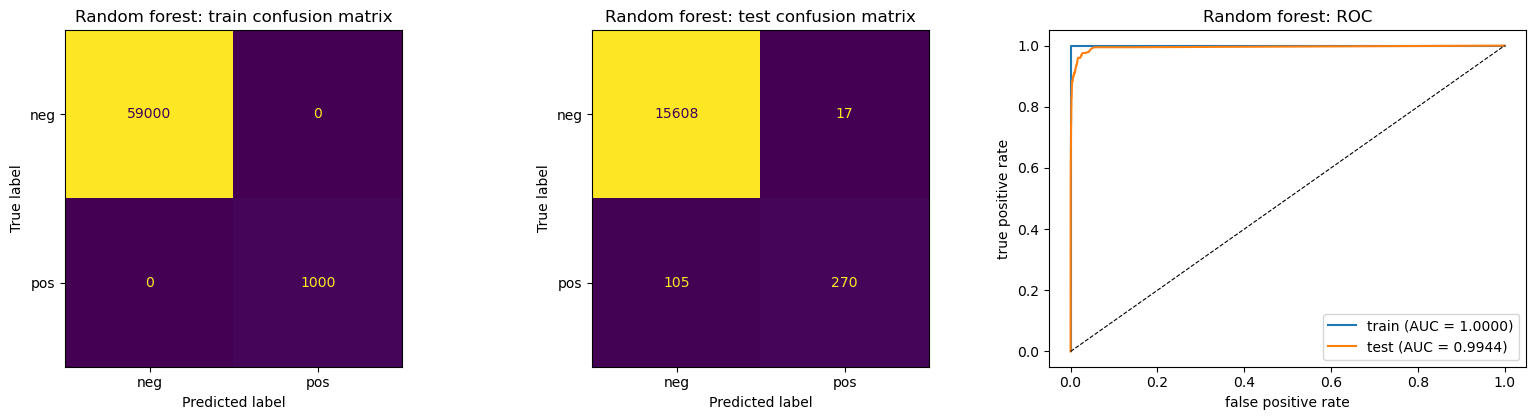

            AUC  misclassification  false negatives  false positives
train  1.000000           0.000000              0.0              0.0
test   0.994446           0.007625            105.0             17.0

Out-of-bag error estimate = 0.0058   vs   test error = 0.0076


In [11]:
t0 = time.time()
rand_forest = RandomForestClassifier(n_estimators=300, oob_score=True,
                            n_jobs=N_JOBS, random_state=SEED).fit(X_tra, y_train)
print(f'trained in {time.time() - t0:.0f} s')
results_rf = evaluate(rand_forest, 'Random forest')
oob_error = 1 - rand_forest.oob_score_
print(f'\nOut-of-bag error estimate = {oob_error:.4f}   vs   test error = {results_rf.loc["test", "misclassification"]:.4f}')


In the training data we have no errors so an AUC of 1.000. In the test data the AUC drops to 0.9944 and we get a misclassification of 0.76%. Most of these errors come from the model favoring the majority class. The OOB error is 0.58% while the test error is 0.76% so the OOB error is smaller making it better. We know part of the reason why the test error is higher is because it has more postives.



### (d) Research class imbalance in random forest

trained in 27 s


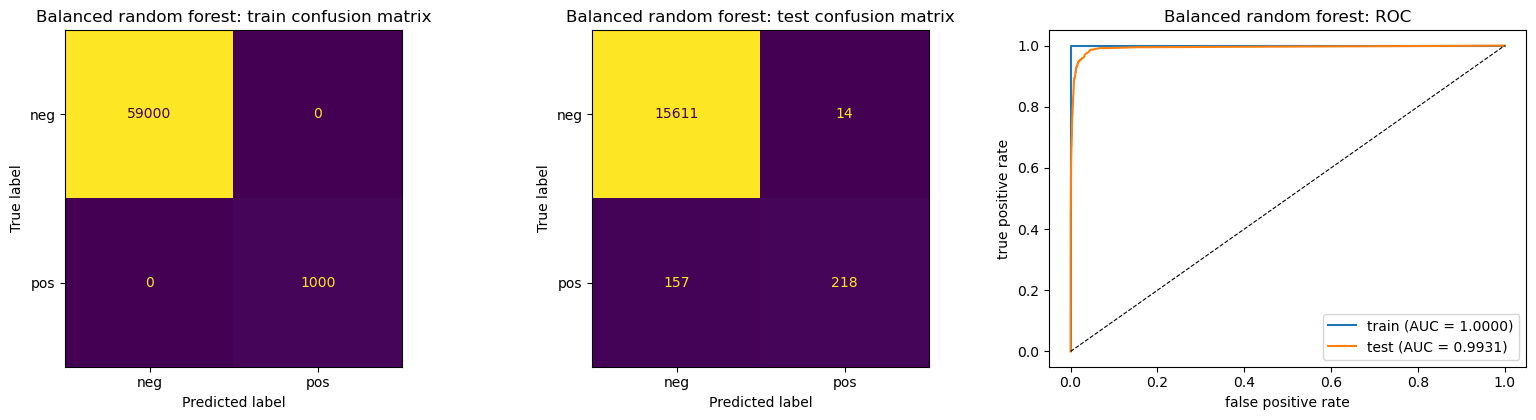

            AUC  misclassification  false negatives  false positives
train  1.000000           0.000000              0.0              0.0
test   0.993082           0.010687            157.0             14.0

Out-of-bag error estimate = 0.0077   vs   test error = 0.0107


,no compensation,class weights
AUC,0.994446,0.993082
misclassification,0.007625,0.010687
false negatives,105.000000,157.000000
false positives,17.000000,14.000000


In [12]:
t0 = time.time()
rand_forest_bal = RandomForestClassifier(n_estimators=300, oob_score=True, class_weight='balanced_subsample',
                                n_jobs=N_JOBS, random_state=SEED).fit(X_tra, y_train)
print(f'trained in {time.time() - t0:.0f} s')
results_rf_bal = evaluate(rand_forest_bal, 'Balanced random forest')
oob_error_bal = 1 - rand_forest_bal.oob_score_
print(f'\nOut-of-bag error estimate = {oob_error_bal:.4f}   vs   test error = {results_rf_bal.loc["test", "misclassification"]:.4f}')
pd.DataFrame({'no compensation': results_rf.loc['test'], 'class weights': results_rf_bal.loc['test']})

So a couple methods to imbalance within random forests are: balanced bootstrap samples, class weights, and resmaplign data. I went with class weights and made it where missclassfying the class costs more when choosing splits. It didn't end up helpign at all. We can see that test missclassification actually rose from 0.76% to 1.07% and false negatives also went up from 105 to 157. Finally our test error was also higher at 1.07% than the OOB error which was .77%.

### (e) XGBoost and Model Trees

In [13]:
XGB_PARAMETERS = dict(objective='binary:logistic', n_estimators=300, learning_rate=0.1,
                  max_depth=4, subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                  eval_metric='logloss', random_state=SEED, n_jobs=N_JOBS)
ALPHAS = [0, 0.01, 0.1, 1, 10]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

t0 = time.time()
xgb_gs = GridSearchCV(xgb.XGBClassifier(**XGB_PARAMETERS), {'reg_alpha': ALPHAS},
                      cv=cv5, scoring='roc_auc', n_jobs=1).fit(X_tra, y_train)
print(f'CV done in {time.time() - t0:.0f} s')
print(pd.DataFrame({'reg_alpha': ALPHAS, 'CV AUC': xgb_gs.cv_results_['mean_test_score']}).round(5).to_string(index=False))
best_alpha = xgb_gs.best_params_['reg_alpha']
print(f'\nalpha chosen by 5-fold CV: {best_alpha}')

CV done in 90 s
 reg_alpha  CV AUC
      0.00 0.98838
      0.01 0.98776
      0.10 0.98791
      1.00 0.98789
     10.00 0.98985

alpha chosen by 5-fold CV: 10


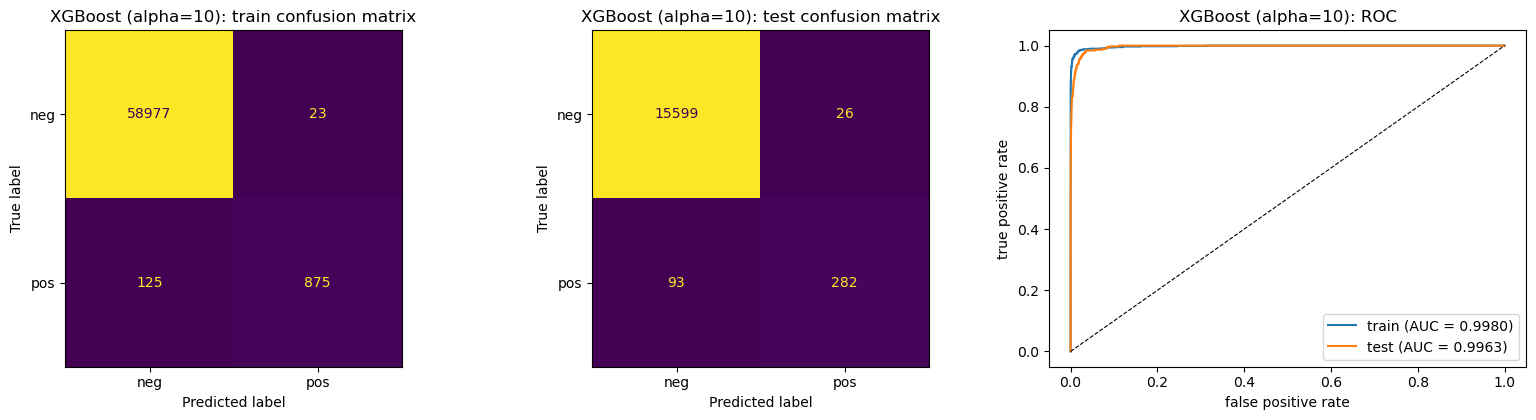

            AUC  misclassification  false negatives  false positives
train  0.997967           0.002467            125.0             23.0
test   0.996320           0.007437             93.0             26.0

5-fold CV error estimate = 0.0066   vs   test error = 0.0074


In [ ]:

best_xgb = xgb.XGBClassifier(**XGB_PARAMETERS, reg_alpha=best_alpha)
cv_error = 1 - cross_val_score(best_xgb, X_tra, y_train, cv=cv5, scoring='accuracy').mean()

best_xgb.fit(X_tra, y_train)
results_xgb = evaluate(best_xgb, f'XGBoost (alpha={best_alpha})')
print(f'\n5-fold CV error estimate = {cv_error:.4f}   vs   test error = {results_xgb.loc["test", "misclassification"]:.4f}')

So the best alpha was 10 chosen by the 5-fold CV. Our test error of 0.74% was bigger than the 5-fold CV error which came in at 0.66%. In training we had an AUC of 0.9980 and missclassification of 0.25% and in testing we had an AUC of 0.9963 and a missclassification of 0.74%. Here we actaully see our best AUC so far out of all the models. 

### (f) Use SMOTE to pre-process your data

In [15]:
def smote_pipe(alpha):
    return ImbPipeline([('scale', StandardScaler()),
                        ('smote', SMOTE(random_state=SEED, k_neighbors=5)),
                        ('xgb', xgb.XGBClassifier(**XGB_PARAMETERS, reg_alpha=alpha))])

t0 = time.time()
smote_gs = GridSearchCV(smote_pipe(0), {'xgb__reg_alpha': ALPHAS}, cv=cv5, scoring='roc_auc', n_jobs=1).fit(X_tra, y_train)
print(f'CV done in {time.time() - t0:.0f} s')
print(pd.DataFrame({'reg_alpha': ALPHAS, 'CV AUC': smote_gs.cv_results_['mean_test_score']}).round(5).to_string(index=False))
best_alpha_smote = smote_gs.best_params_['xgb__reg_alpha']
print(f'\nalpha chosen by 5-fold CV (SMOTE inside each fold): {best_alpha_smote}')

CV done in 172 s
 reg_alpha  CV AUC
      0.00 0.98735
      0.01 0.98806
      0.10 0.98794
      1.00 0.98793
     10.00 0.98691

alpha chosen by 5-fold CV (SMOTE inside each fold): 0.01


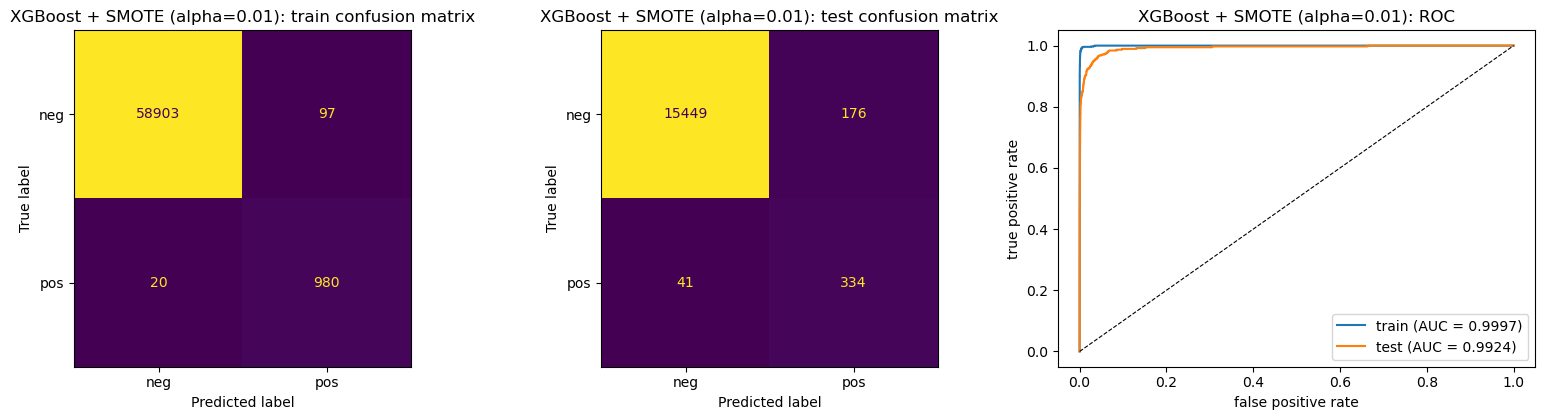

            AUC  misclassification  false negatives  false positives
train  0.999731           0.001950             20.0             97.0
test   0.992432           0.013563             41.0            176.0

5-fold CV error estimate = 0.0078   vs   test error = 0.0136


In [ ]:
best_smote = smote_pipe(best_alpha_smote)
cv_error_smote = 1 - cross_val_score(best_smote, X_tra, y_train, cv=cv5, scoring='accuracy').mean()

best_smote.fit(X_tra, y_train)
results_smote = evaluate(best_smote, f'XGBoost + SMOTE (alpha={best_alpha_smote})')
print(f'\n5-fold CV error estimate = {cv_error_smote:.4f}   vs   test error = {results_smote.loc["test", "misclassification"]:.4f}')

To do cross-validation the right way we only applied SMOTE to the training folds during cross-validation and never to the validation folds. SMOTE was good and bad it dropped missed failures from 93 to 41 but lifted false alarms from 26 to 176. This caused our test error to go up from 0.74% to 1.36% and our AUC went down a little bit. Although total cost goes down from 46,760 to 22,260 menaing SMOTE is the better pick in this case.

## 2. ISLR 6.6.3

(a) iv, steadily decreases. The trainign fit can only improve because the larger s loosens the contraint.

(b) ii, Decreases, then increases (U shape). We can see that in the beginning the bias goes down and then variance takes over.

(c) iii, Steadily increases. Because we dont see much shrinking the the fit is more dependent on the sample.

(d) iv, Steadil decreases. As time goes on the model becomes more flexible.

(e) v, Remains constant. This error doesn't rely on the model.

## 3. ISLR 6.6.5

If we say x₁₁ = x₁₂ = x, x₂₁ = x₂₂ = −x, y₁ = y and y₂ = −y (so β̂₀ = 0). Thus, there squared terms will equal up to (y − (β₁ + β₂)x)².

(a) Ridge:

$$
\min_{\beta_1,\beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2) \;=\; 2\big(y - (\beta_1+\beta_2)x\big)^2 + \lambda(\beta_1^2 + \beta_2^2)
$$

(b) Have to set both partial derivatives to 0:

$$
-4x\big(y - (\beta_1+\beta_2)x\big) + 2\lambda\beta_1 = 0, \qquad -4x\big(y - (\beta_1+\beta_2)x\big) + 2\lambda\beta_2 = 0
$$

Then we subtract to get 2λβ₁ = 2λβ₂, so **β̂₁ = β̂₂** (λ > 0).

(c) Lasso:

$$
\min_{\beta_1,\beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|) \;=\; 2\big(y - (\beta_1+\beta_2)x\big)^2 + \lambda(|\beta_1| + |\beta_2|)
$$


(d) We know the RSS depends only on β₁ + β₂. We also know |β₁| + |β₂| = |β₁ + β₂| when β₁ and β₂ have the same sign. Although the solutions are not unique this is because every same-sign pair with the optimal sum gives the same minimum. The RSS contour are lines β₁ + β₂ = constant, parallel to the lasso diamond, thus the solution is that whole edge of β̂₁ + β̂₂ = s where β̂₁, β̂₂ ≥ 0.

## 4. ISLR 8.4.5

 Majority vote: 6 of the 10 estimates are over 0.5, Red.
Average probability: 4.5 / 10 = 0.45 < 0.5, Green.

## 5. ISLR 9.7.3

Red: (3,4), (2,2), (4,4), (1,4). Blue: (2,1), (4,3), (4,1).

- (a) Look at plot below.
- (b) The hyperplane runs in the middle between the closest pairs, Red (2,2)/Blue (2,1) and Red (4,4)/Blue (4,3): 0.5 − X₁ + X₂ = 0, so X₂ = X₁ − 0.5.
- (c) Classify as Red if 0.5 − X₁ + X₂ > 0, if not then its Blue (β₀ = 0.5, β₁ = −1, β₂ = 1).
- (d) Margin = |0.5 − 2 + 2| / √2 = 0.5/√2 ≈ 0.354.
- (e) Support vectors: (2,2), (4,4), (2,1), (4,3).
- (f) (4,1) is not a support vector, meaning if we move it a little bit this doesn't change the hyperplane.
- (g) Example, 0.1 − X₁ + X₂ = 0: it still separates the classes, but with a smaller margin.
- (h) Example, take a Red point at (4,2): it lies between the Blue points (4,1) and (4,3), meaning no line can separate the hyperplane.

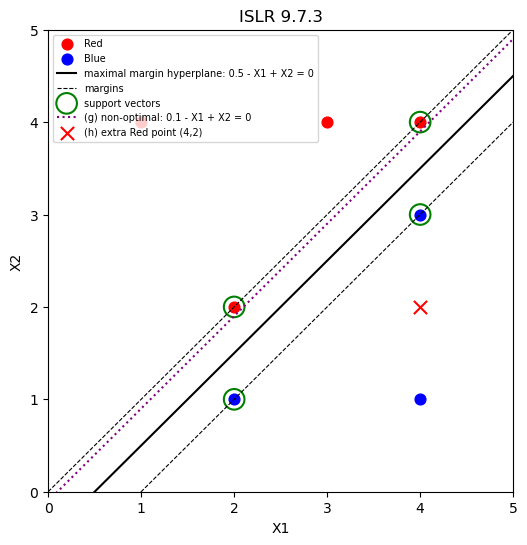

In [ ]:
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]]); blue = np.array([[2, 1], [4, 3], [4, 1]])
x = np.linspace(0, 5, 100)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*red.T, c='red', s=60, label='Red'); ax.scatter(*blue.T, c='blue', s=60, label='Blue')
ax.plot(x, x - 0.5, 'k-', label='maximal margin hyperplane: 0.5 - X1 + X2 = 0')
ax.plot(x, x, 'k--', lw=.8); ax.plot(x, x - 1, 'k--', lw=.8, label='margins')
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
ax.scatter(*sv.T, s=220, facecolors='none', edgecolors='green', linewidths=1.5, label='support vectors')
ax.plot(x, x - 0.1, ':', color='purple', label='(g) non-optimal: 0.1 - X1 + X2 = 0')
ax.scatter([4], [2], marker='x', c='red', s=90, label='(h) extra Red point (4,2)')
ax.set(xlim=(0, 5), ylim=(0, 5), xlabel='X1', ylabel='X2', title='ISLR 9.7.3'); ax.legend(fontsize=7, loc='upper left')
plt.show()